In [1]:
import os
import numpy as np
import random
import matplotlib.pyplot as plt

from PIL import Image, ImageEnhance


from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    GlobalAveragePooling2D
)

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input


from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)


from tensorflow.keras.preprocessing.image import load_img


from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
import math

In [2]:
train_dir = '/content/drive/MyDrive/archive/Training'
test_dir = '/content/drive/MyDrive/archive/Testing'

train_paths = []
train_labels = []


for label in sorted(os.listdir(train_dir)):
    class_dir = os.path.join(train_dir, label)
    if not os.path.isdir(class_dir):
        continue
    for image in os.listdir(class_dir):
        image_path = os.path.join(class_dir, image)
        if os.path.isfile(image_path):
            train_paths.append(image_path)
            train_labels.append(label)


train_paths, train_labels = shuffle(train_paths, train_labels, random_state=42)

test_paths = []
test_labels = []


for label in sorted(os.listdir(test_dir)):
    class_dir = os.path.join(test_dir, label)
    if not os.path.isdir(class_dir):
        continue
    for image in os.listdir(class_dir):
        image_path = os.path.join(class_dir, image)
        if os.path.isfile(image_path):
            test_paths.append(image_path)
            test_labels.append(label)


test_paths, test_labels = shuffle(test_paths, test_labels, random_state=42)

print("Training images:", len(train_paths))
print("Testing images:", len(test_paths))

print("\nTraining classes:", sorted(set(train_labels)))
print("Testing classes:", sorted(set(test_labels)))

Training images: 5600
Testing images: 1600

Training classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Testing classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [3]:
IMAGE_SIZE = 224
BATCH_SIZE = 20


class_names = sorted(set(train_labels))
class_to_index = {
    name: index for index, name in enumerate(class_names)
}

print("Class mapping:", class_to_index)


def augment_image(image):
    image = Image.fromarray(np.uint8(image))


    image = ImageEnhance.Brightness(image).enhance(
        random.uniform(0.85, 1.15)
    )


    image = ImageEnhance.Contrast(image).enhance(
        random.uniform(0.85, 1.15)
    )

    return np.array(image)


def encode_labels(labels):
    return np.array(
        [class_to_index[label] for label in labels],
        dtype=np.int32
    )


def open_images(paths, augment=False):
    images = []
    for path in paths:
        image = Image.open(path).convert('RGB')
        image = image.resize((IMAGE_SIZE, IMAGE_SIZE))
        image = np.array(image)
        if augment:
            image = augment_image(image)
        images.append(image)
    images = np.array(images, dtype=np.float32)

    images = preprocess_input(images)
    return images


def datagen(paths, labels, batch_size=BATCH_SIZE, augment=False):
    paths = np.array(paths)
    labels = np.array(labels)
    while True:
        indices = np.random.permutation(len(paths))
        for i in range(0, len(paths), batch_size):
            batch_indices = indices[i:i + batch_size]
            batch_paths = paths[batch_indices]
            batch_labels = labels[batch_indices]
            batch_images = open_images(
                batch_paths,
                augment=augment
            )
            batch_labels = encode_labels(batch_labels)
            yield batch_images, batch_labels

Class mapping: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


In [ ]:
train_paths, validation_paths, train_labels, validation_labels = train_test_split(
    train_paths,
    train_labels,
    test_size=0.20,
    random_state=42,
    stratify=train_labels
)

print("Training images:", len(train_paths))
print("Validation images:", len(validation_paths))
print("Testing images:", len(test_paths))

IMAGE_SIZE = 224
BATCH_SIZE = 20

base_model = VGG16(
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    include_top=False,
    weights='imagenet'
)


base_model.trainable = False

model = Sequential([
    Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3)),
    base_model,
    GlobalAveragePooling2D(),
    Dropout(0.4),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(4, activation='softmax')
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

train_generator = datagen(
    train_paths,
    train_labels,
    batch_size=BATCH_SIZE,
    augment=True
)

validation_generator = datagen(
    validation_paths,
    validation_labels,
    batch_size=BATCH_SIZE,
    augment=False
)

steps_per_epoch = math.ceil(len(train_paths) / BATCH_SIZE)
validation_steps = math.ceil(len(validation_paths) / BATCH_SIZE)

callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=2,
        min_lr=1e-7
    ),
    ModelCheckpoint(
        'best_vgg16_phase1.keras',
        monitor='val_loss',
        save_best_only=True
    )
]

Training images: 3584
Validation images: 896
Testing images: 1600


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,847,044 (56.64 MB)

 Trainable params: 132,356 (517.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
history1 = model.fit(
    train_generator,
    epochs=10,
    steps_per_epoch=steps_per_epoch,
    validation_data=validation_generator,
    validation_steps=validation_steps,
    callbacks=callbacks
)

base_model.trainable = True

for layer in base_model.layers:
    if layer.name.startswith('block5_'):
        layer.trainable = True
    else:
        layer.trainable = False

for layer in base_model.layers:
    print(layer.name, layer.trainable)

model.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_phase2 = [
    EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=2,
        min_lr=1e-7
    ),
    ModelCheckpoint(
        'best_vgg16_phase2.keras',
        monitor='val_loss',
        save_best_only=True
    )
]

history2 = model.fit(
    train_generator,
    epochs=15,
    steps_per_epoch=steps_per_epoch,
    validation_data=validation_generator,
    validation_steps=validation_steps,
    callbacks=callbacks_phase2
)

Epoch 1/10
180/180 ━━━━━━━━━━━━━━━━━━━━ 2484s 14s/step - accuracy: 0.6222 - loss: 1.6020 - val_accuracy: 0.8605 - val_loss: 0.3787 - learning_rate: 0.0010
Epoch 2/10
180/180 ━━━━━━━━━━━━━━━━━━━━ 52s 289ms/step - accuracy: 0.7414 - loss: 0.6940 - val_accuracy: 0.8661 - val_loss: 0.4081 - learning_rate: 0.0010
Epoch 3/10
180/180 ━━━━━━━━━━━━━━━━━━━━ 52s 289ms/step - accuracy: 0.7871 - loss: 0.5565 - val_accuracy: 0.8594 - val_loss: 0.3931 - learning_rate: 0.0010
Epoch 4/10
180/180 ━━━━━━━━━━━━━━━━━━━━ 53s 296ms/step - accuracy: 0.8072 - loss: 0.5138 - val_accuracy: 0.8850 - val_loss: 0.3460 - learning_rate: 2.0000e-04
Epoch 5/10
180/180 ━━━━━━━━━━━━━━━━━━━━ 53s 296ms/step - accuracy: 0.8184 - loss: 0.4884 - val_accuracy: 0.8984 - val_loss: 0.3267 - learning_rate: 2.0000e-04
Epoch 6/10
180/180 ━━━━━━━━━━━━━━━━━━━━ 52s 290ms/step - accuracy: 0.8217 - loss: 0.4570 - val_accuracy: 0.8828 - val_loss: 0.3369 - learning_rate: 2.0000e-04
Epoch 7/10
180/180 ━━━━━━━━━━━━━━━━━━━━ 50s 278ms/step - a

In [ ]:
model.save('/content/drive/MyDrive/brain_tumor_vgg16.keras')

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
from tensorflow.keras.models import load_model

model = load_model(
    '/content/drive/MyDrive/brain_tumor_vgg16.keras'
    )

print("Model loaded successfully!")

Model loaded successfully!


In [10]:
import os
import json

train_dir = '/content/drive/MyDrive/archive/Training'

class_names = sorted([
    name for name in os.listdir(train_dir)
    if os.path.isdir(os.path.join(train_dir, name))
])

print("Class names:", class_names)

class_to_index = {
    name: index for index, name in enumerate(class_names)
}
print(class_to_index)

with open('/content/drive/MyDrive/brain_tumor_classes.json', 'w') as f:
    json.dump(class_names, f)

Class names: ['glioma', 'meningioma', 'notumor', 'pituitary']
{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


Test Accuracy: 91.81%

Classification Report:
              precision    recall  f1-score   support

      glioma     0.9807    0.7625    0.8579       400
  meningioma     0.8747    0.9250    0.8991       400
     notumor     0.8926    0.9975    0.9421       400
   pituitary     0.9427    0.9875    0.9646       400

    accuracy                         0.9181      1600
   macro avg     0.9227    0.9181    0.9160      1600
weighted avg     0.9227    0.9181    0.9160      1600


Confusion Matrix:
[[305  48  39   8]
 [  5 370   9  16]
 [  0   1 399   0]
 [  1   4   0 395]]


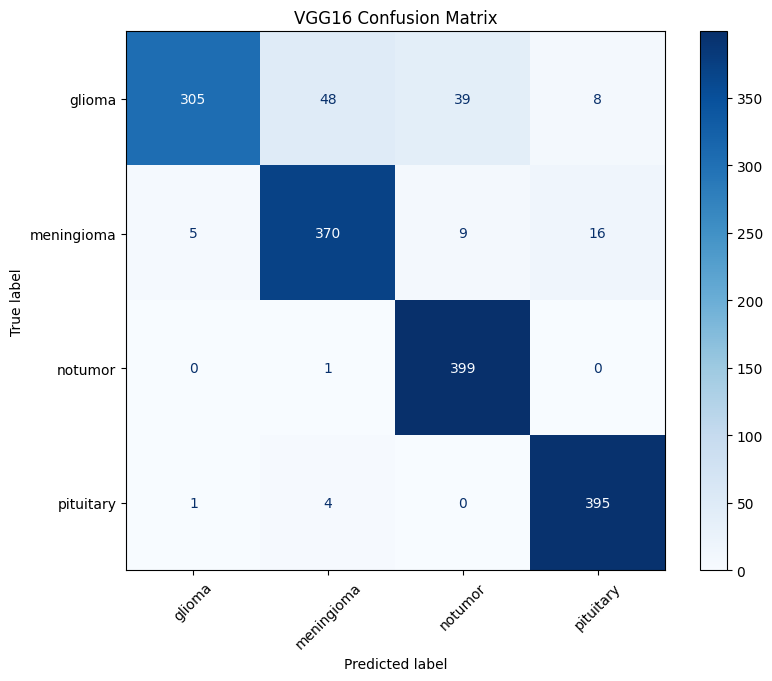

In [12]:
import numpy as np
import math
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


y_true = encode_labels(test_labels)


y_pred = []

for i in range(0, len(test_paths), BATCH_SIZE):
    batch_paths = test_paths[i:i + BATCH_SIZE]
    batch_images = open_images(batch_paths, augment=False)
    predictions = model.predict(batch_images, verbose=0)
    y_pred.extend(np.argmax(predictions, axis=1))

y_pred = np.array(y_pred)


print(f"Test Accuracy: {accuracy_score(y_true, y_pred) * 100:.2f}%")


print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))


cm = confusion_matrix(y_true, y_pred)

print("\nConfusion Matrix:")
print(cm)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title("VGG16 Confusion Matrix")
plt.xticks(rotation=45)
plt.show()

Saving men.jpeg to men (1).jpeg


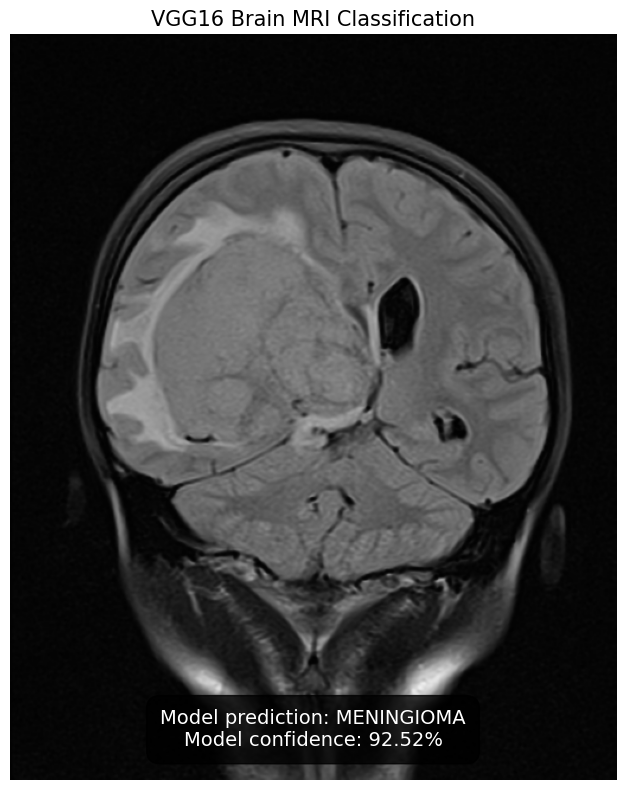


Class-wise model scores:
glioma: 0.73%
meningioma: 92.52%
notumor: 6.22%
pituitary: 0.53%


In [17]:
from google.colab import files
from PIL import Image
from io import BytesIO
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications.vgg16 import preprocess_input

def predict_brain_mri():

    uploaded = files.upload()

    if not uploaded:
        print("No image uploaded.")
        return


    filename = next(iter(uploaded))

    try:
        image = Image.open(BytesIO(uploaded[filename])).convert('RGB')
    except Exception:
        print("Invalid image file. Please upload a valid image.")
        return


    original_image = image.copy()
    image = image.resize((IMAGE_SIZE, IMAGE_SIZE))

    image_array = np.array(image, dtype=np.float32)
    image_array = np.expand_dims(image_array, axis=0)
    image_array = preprocess_input(image_array)


    predictions = model.predict(image_array, verbose=0)[0]

    predicted_index = np.argmax(predictions)
    predicted_class = class_names[predicted_index]
    confidence = predictions[predicted_index] * 100


    fig, ax = plt.subplots(figsize=(8, 8))

    ax.imshow(original_image)
    ax.axis('off')

    result_text = (
        f"Model prediction: {predicted_class.upper()}\n"
        f"Model confidence: {confidence:.2f}%"
    )

    ax.text(
        0.5, 0.04,
        result_text,
        transform=ax.transAxes,
        fontsize=14,
        color='white',
        ha='center',
        va='bottom',
        bbox=dict(
            facecolor='black',
            alpha=0.8,
            boxstyle='round,pad=0.7'
        )
    )

    plt.title("VGG16 Brain MRI Classification", fontsize=15)
    plt.tight_layout()
    plt.show()


    print("\nClass-wise model scores:")
    for name, score in zip(class_names, predictions):
        print(f"{name}: {score * 100:.2f}%")




predict_brain_mri()